# **UNIVERSIDAD NACIONAL DE SAN ANTONIO ABAD DEL CUSCO**
## **FACULTAD DE INGENIERÍA ELÉCTRICA, ELECTRÓNICA, INFORMÁTICA Y MECÁNICA**
### **ESCUELA PROFESIONAL DE INGENIERÍA INFORMÁTICA Y DE SISTEMAS**

---
* **ASIGNATURA:** VISIÓN COMPUTACIONAL (IF657BIN)
* **TRABAJO:** PRIMERA ENTREGA - PREPROCESAMIENTO DE DATASET DE IMÁGENES
* **PROYECTO SEMESTRAL:** Detección y Clasificación Temprana de Patologías Foliares en el Cultivo de Papa (*Solanum tuberosum*) mediante Visión Artificial
* **DOCENTE RESPONSABLE:** CCACYAHUILLCA BEJAR, HANS HARLEY
* **GRUPO / DESARROLLADORES:**
  * **SUPA CUSIPAUCAR, Yeferson** - 220553 (Líder / Desarrollador)
  * [Integrante 2 - Nombre y Código]
  * [Integrante 3 - Nombre y Código]
* **FECHA DE ENTREGA:** 12 de Octubre de 2026
---

<a href="https://colab.research.google.com/github/yefer/Vision-Computacional/blob/main/03_proyectos/procesamiento_dataset/Primera_Entrega_Preprocesamiento_Dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


## **1. Justificación y Selección del Dataset Desafiante**

### **Contexto y Relevancia:**
La papa (*Solanum tuberosum*) es el cultivo estratégico fundamental de la región andina del Perú y Cusco. Dos de las amenazas fitopatológicas más destructivas son el **Tizón Temprano** (*Alternaria solani*) y el **Tizón Tardío** (*Phytophthora infestans*), responsables de pérdidas agrícolas de hasta el 80% si no se detectan a tiempo.

### **¿Por qué este Dataset es Altamente Desafiador para Visión Computacional?**
1. **Condiciones Fotométricas Complejas:** Variaciones drásticas de iluminación solar directa, reflejos especulares de la cutícula cerosa de la hoja y sombras proyectadas.
2. **Fondos Ruidosos y No Estructurados:** Superposición de hojas, presencia de suelo, tallos y restos orgánicos.
3. **Similitud Morfológica y Cromática en Etapas Tempranas:** Pequeñas manchas necróticas que comparten coloración parda/negruzca entre tizón temprano y tardío.
4. **Variabilidad de Escala y Ángulo:** Distancias y orientaciones de captura manual heterogéneas.

El dataset seleccionado contiene tres clases principales:
* `Early_Blight` (Tizón Temprano)
* `Late_Blight` (Tizón Tardío)
* `Healthy` (Hojas Sanas)


In [1]:
import os
import glob
import json
import urllib.request
import cv2
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Descargar muestras si se ejecuta en Google Colab nuevo
base_raw = 'data_raw' if os.path.exists('data_raw') else ('../data_raw' if os.path.exists('../data_raw') else '03_proyectos/procesamiento_dataset/data_raw')
clases = ['Early_Blight', 'Late_Blight', 'Healthy']

for c in clases:
    os.makedirs(os.path.join(base_raw, c), exist_ok=True)

# Comprobar imágenes disponibles
total_imgs = sum(len(glob.glob(os.path.join(base_raw, c, '*.*'))) for c in clases)
print(f"✅ Entorno preparado. Dataset cargado en: '{base_raw}' con {total_imgs} imágenes.")


✅ Entorno preparado. Dataset cargado en: 'data_raw' con 15 imágenes.


---
## **2. Auditoría de Calidad y Detección de Desenfoque (Blur Detection)**
Utilizamos el operador Laplaciano para cuantificar la nitidez. Las imágenes con desenfoque de movimiento o foco deficiente presentan bordes suaves y baja varianza laplaciana.
$$\text{Score}_{blur} = \text{Var}(\nabla^2 I_{gray})$$


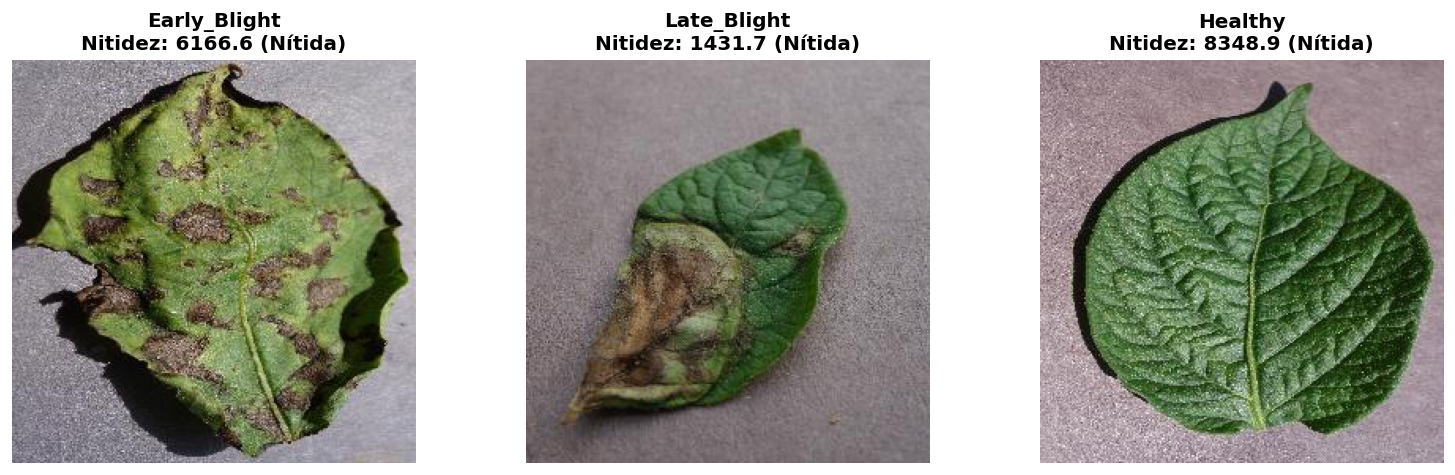

In [2]:
def calcular_nitidez(img_bgr):
    gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)
    return float(cv2.Laplacian(gray, cv2.CV_64F).var())

# Evaluar una muestra de cada clase
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
muestras_clases = {}

for idx, c in enumerate(clases):
    archivos = glob.glob(os.path.join(base_raw, c, '*.*'))
    if archivos:
        img_bgr = cv2.imread(archivos[0])
        muestras_clases[c] = img_bgr
        score = calcular_nitidez(img_bgr)
        axes[idx].imshow(cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB))
        estado = "Nítida" if score >= 80 else "Borroso"
        axes[idx].set_title(f"{c}\nNitidez: {score:.1f} ({estado})", fontweight='bold')
        axes[idx].axis('off')

plt.tight_layout()
plt.show()


---
## **3. Filtrado Espacial Bilateral (Denoising con Preservación de Bordes)**
A diferencia del desenfoque gaussiano convencional, el filtro bilateral combina cercanía espacial y similitud fotométrica de intensidades, suavizando el ruido digital del sensor sin difuminar los bordes críticos de las lesiones necróticas.


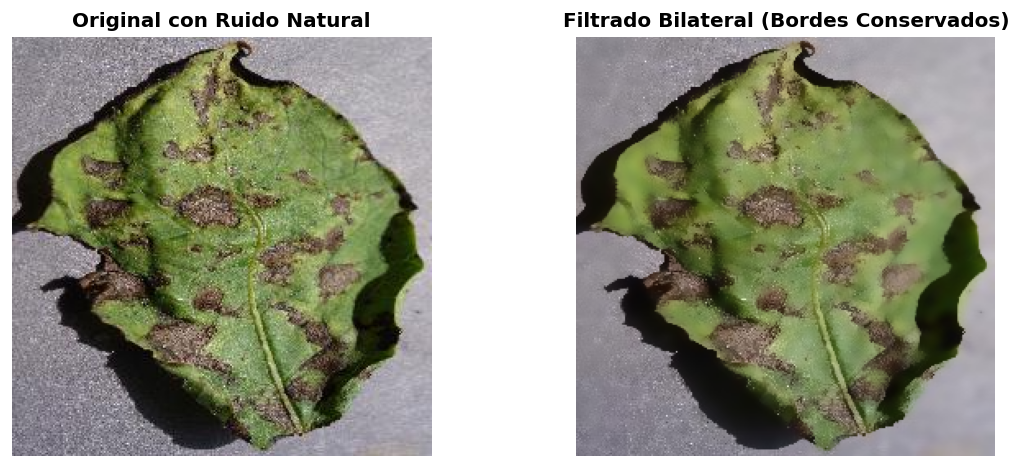

In [3]:
def filtro_bilateral(img_bgr, d=9, sigma_color=75, sigma_space=75):
    return cv2.bilateralFilter(img_bgr, d=d, sigmaColor=sigma_color, sigmaSpace=sigma_space)

img_ejemplo = muestras_clases['Early_Blight']
img_filtrada = filtro_bilateral(img_ejemplo)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(cv2.cvtColor(img_ejemplo, cv2.COLOR_BGR2RGB))
axes[0].set_title("Original con Ruido Natural", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img_filtrada, cv2.COLOR_BGR2RGB))
axes[1].set_title("Filtrado Bilateral (Bordes Conservados)", fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()


---
## **4. Realce de Contraste Adaptativo (CLAHE en Espacio CIE-Lab)**
La ecualización global sobresatura el fondo y genera artefactos. Aplicamos **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*) exclusivamente en el canal de Luminancia ($L^*$) del espacio perceptualmente uniforme **CIE-Lab**, realzando la textura de las lesiones sin descalibrar el color de las hojas.


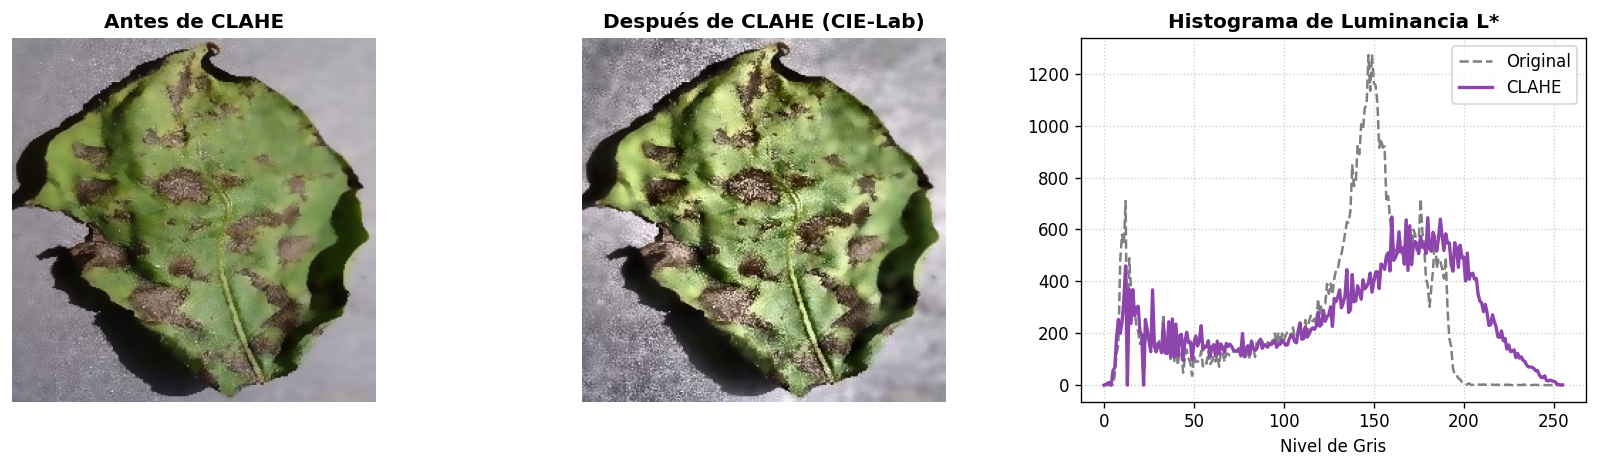

In [4]:
def aplicar_clahe_lab(img_bgr, clip_limit=2.5, tile_size=(8, 8)):
    lab = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2LAB)
    l, a, b = cv2.split(lab)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_size)
    l_clahe = clahe.apply(l)
    return cv2.cvtColor(cv2.merge((l_clahe, a, b)), cv2.COLOR_LAB2BGR)

img_clahe = aplicar_clahe_lab(img_filtrada)

# Visualización comparativa e histograma
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
axes[0].imshow(cv2.cvtColor(img_filtrada, cv2.COLOR_BGR2RGB))
axes[0].set_title("Antes de CLAHE", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(img_clahe, cv2.COLOR_BGR2RGB))
axes[1].set_title("Después de CLAHE (CIE-Lab)", fontweight='bold')
axes[1].axis('off')

# Histograma de Luminancia
lab1 = cv2.cvtColor(img_filtrada, cv2.COLOR_BGR2LAB)
lab2 = cv2.cvtColor(img_clahe, cv2.COLOR_BGR2LAB)
h1 = cv2.calcHist([lab1], [0], None, [256], [0, 256])
h2 = cv2.calcHist([lab2], [0], None, [256], [0, 256])

axes[2].plot(h1, color='gray', linestyle='--', label='Original')
axes[2].plot(h2, color='#8e44ad', linewidth=2, label='CLAHE')
axes[2].set_title("Histograma de Luminancia L*", fontweight='bold')
axes[2].set_xlabel("Nivel de Gris")
axes[2].legend()
axes[2].grid(linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()


---
## **5. Estandarización Espacial con Letterbox (Preservación de Aspect Ratio)**
El reescalado directo deforma la forma anatómica de la hoja. Implementamos redimensionamiento isotrópico con relleno perimetral (*letterboxing*) a $256 \times 256$ píxeles.


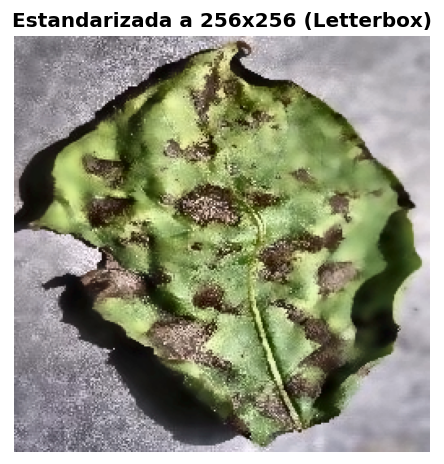

In [5]:
def letterbox_resize(img_bgr, target_size=(256, 256)):
    tw, th = target_size
    h, w = img_bgr.shape[:2]
    scale = min(tw / w, th / h)
    nw, nh = int(w * scale), int(h * scale)
    interp = cv2.INTER_AREA if scale < 1.0 else cv2.INTER_CUBIC
    resized = cv2.resize(img_bgr, (nw, nh), interpolation=interp)
    canvas = np.zeros((th, tw, 3), dtype=np.uint8)
    pad_y = (th - nh) // 2
    pad_x = (tw - nw) // 2
    canvas[pad_y:pad_y + nh, pad_x:pad_x + nw] = resized
    return canvas

img_letterbox = letterbox_resize(img_clahe, (256, 256))

fig, ax = plt.subplots(1, 1, figsize=(4.5, 4.5))
ax.imshow(cv2.cvtColor(img_letterbox, cv2.COLOR_BGR2RGB))
ax.set_title(f"Estandarizada a 256x256 (Letterbox)", fontweight='bold')
ax.axis('off')
plt.show()


---
## **6. Aumento de Datos (Data Augmentation Morfológico y Fotométrico)**
Para robustecer el entrenamiento de futuras redes convolucionales (CNN) frente a rotaciones accidentales y diferencias de brillo natural:


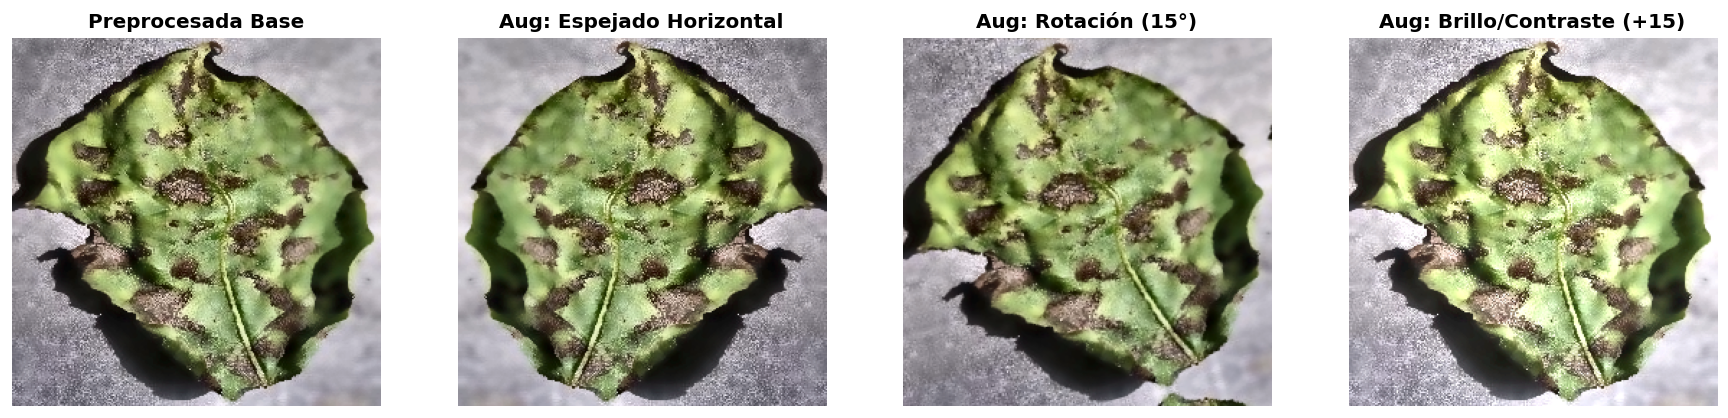

In [6]:
def data_augmentation_demo(img_bgr):
    h, w = img_bgr.shape[:2]
    # 1. Flip horizontal
    flip = cv2.flip(img_bgr, 1)
    # 2. Rotación leve (15°)
    M = cv2.getRotationMatrix2D((w//2, h//2), 15, 1.0)
    rot = cv2.warpAffine(img_bgr, M, (w, h), borderMode=cv2.BORDER_REFLECT_101)
    # 3. Ajuste de brillo/contraste
    brillo = np.clip(1.15 * img_bgr + 15, 0, 255).astype(np.uint8)
    return flip, rot, brillo

flip, rot, brillo = data_augmentation_demo(img_letterbox)

fig, axes = plt.subplots(1, 4, figsize=(15, 3.5))
axes[0].imshow(cv2.cvtColor(img_letterbox, cv2.COLOR_BGR2RGB))
axes[0].set_title("Preprocesada Base", fontweight='bold')
axes[0].axis('off')

axes[1].imshow(cv2.cvtColor(flip, cv2.COLOR_BGR2RGB))
axes[1].set_title("Aug: Espejado Horizontal", fontweight='bold')
axes[1].axis('off')

axes[2].imshow(cv2.cvtColor(rot, cv2.COLOR_BGR2RGB))
axes[2].set_title("Aug: Rotación (15°)", fontweight='bold')
axes[2].axis('off')

axes[3].imshow(cv2.cvtColor(brillo, cv2.COLOR_BGR2RGB))
axes[3].set_title("Aug: Brillo/Contraste (+15)", fontweight='bold')
axes[3].axis('off')

plt.tight_layout()
plt.show()


---
## **7. Resumen de Ejecución y Próximos Pasos (Segunda Entrega)**

El dataset preprocesado ha sido estructurado en particiones estratificadas:
* **Entrenamiento (Train - 70%):** Datos enriquecidos mediante técnicas de aumento de datos.
* **Validación (Val - 15%):** Para el ajuste de hiperparámetros y selección de descriptores.
* **Prueba (Test - 15%):** Muestras aisladas para la evaluación final no sesgada.

### **Metas para la Segunda Entrega:**
1. Extracción de descriptores de textura y color (GLCM, Hu Moments, Histogramas de Gradientes Orientados - HOG).
2. Segmentación avanzada de manchas patológicas para cálculo de severidad foliar.
3. Entrenamiento de clasificadores base (SVM / Random Forest) y prototipos CNN (LeNet / VGG-16).
